# Student Performance Prediction using Linear Regression



## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the Dataset
Download `StudentsPerformance.csv` from Kaggle and keep it next to this notebook.
If the file is not found, a small sample with the same columns is generated so the notebook still runs.

In [2]:
try:
    df = pd.read_csv("StudentsPerformance.csv")
    print("Loaded Kaggle dataset")
except FileNotFoundError:
    print("CSV not found - using generated sample data (replace with the Kaggle file for real results)")
    rng = np.random.default_rng(42)
    n = 1000
    df = pd.DataFrame({
        "gender": rng.choice(["female", "male"], n),
        "race/ethnicity": rng.choice(["group A", "group B", "group C", "group D", "group E"], n),
        "parental level of education": rng.choice(["some high school", "high school", "some college",
                                                    "associate's degree", "bachelor's degree", "master's degree"], n),
        "lunch": rng.choice(["standard", "free/reduced"], n, p=[0.65, 0.35]),
        "test preparation course": rng.choice(["none", "completed"], n, p=[0.64, 0.36]),
    })
    base = (62 + 7*(df["lunch"] == "standard") + 6*(df["test preparation course"] == "completed")
            + 3*df["parental level of education"].isin(["bachelor's degree", "master's degree"])
            + 2*(df["gender"] == "female") + rng.normal(0, 12, n))
    for s in ["math score", "reading score", "writing score"]:
        df[s] = np.clip(base + rng.normal(0, 5, n), 0, 100).round()

print(df.shape)
df.head()

CSV not found - using generated sample data (replace with the Kaggle file for real results)
(1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group E,master's degree,free/reduced,none,70.0,67.0,78.0
1,male,group D,some high school,free/reduced,completed,90.0,77.0,82.0
2,male,group C,some college,standard,completed,81.0,80.0,75.0
3,female,group E,some college,standard,completed,79.0,70.0,79.0
4,female,group A,bachelor's degree,free/reduced,none,73.0,79.0,66.0


## 3. Explore the Data

In [3]:
print(df.isnull().sum().sum(), "missing values")
df.describe()

0 missing values


,math score,reading score,writing score
count,1000.000000,1000.000000,1000.000000
mean,70.770000,70.991000,70.881000
std,13.146632,13.556131,13.253924
min,30.000000,26.000000,29.000000
25%,61.000000,62.000000,62.000000
50%,71.000000,71.000000,71.000000
75%,80.000000,80.000000,80.000000
max,100.000000,100.000000,100.000000


## 4. Create the Target: Final Score

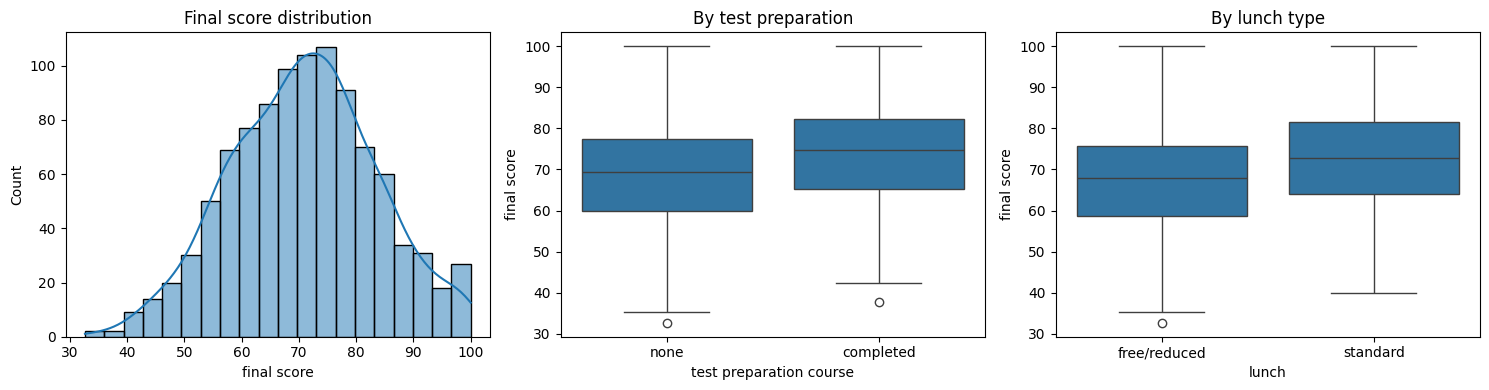

In [4]:
df["final score"] = df[["math score", "reading score", "writing score"]].mean(axis=1).round(2)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["final score"], kde=True, ax=ax[0])
sns.boxplot(data=df, x="test preparation course", y="final score", ax=ax[1])
sns.boxplot(data=df, x="lunch", y="final score", ax=ax[2])
ax[0].set_title("Final score distribution")
ax[1].set_title("By test preparation")
ax[2].set_title("By lunch type")
plt.tight_layout(); plt.show()

## 5. Prepare the Data
Linear Regression needs numbers, so the text columns are converted with one-hot encoding.
The three subject scores are dropped from the inputs because they are what the final score is made from.

In [5]:
X = pd.get_dummies(df.drop(columns=["math score", "reading score", "writing score", "final score"]), drop_first=True)
y = df["final score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 12)  Test: (200, 12)


## 6. Train the Linear Regression Model

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 7. Evaluate the Model

MAE  : 10.25
RMSE : 12.37
R2   : 0.056


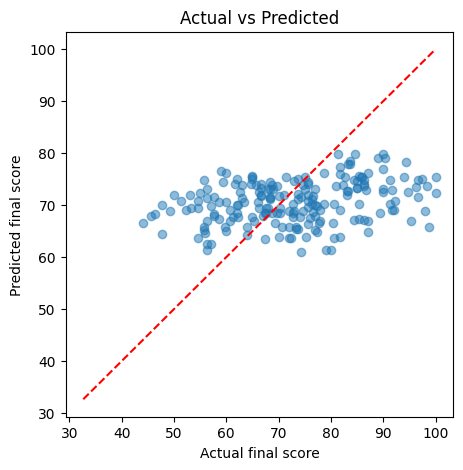

In [7]:
y_pred = model.predict(X_test)

print(f"MAE  : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R2   : {r2_score(y_test, y_pred):.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual final score"); plt.ylabel("Predicted final score")
plt.title("Actual vs Predicted"); plt.show()

## 8. Which Factors Matter Most?

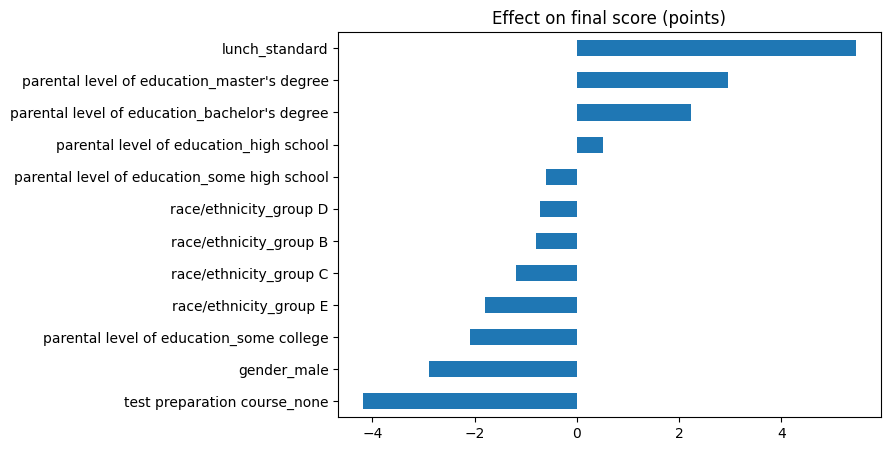

In [8]:
coef = pd.Series(model.coef_, index=X.columns).sort_values()
coef.plot(kind="barh", figsize=(7, 5), title="Effect on final score (points)")
plt.show()

## 9. Predict the Final Score of a New Student

In [9]:
new_student = {
    "gender": "female", "race/ethnicity": "group C",
    "parental level of education": "bachelor's degree",
    "lunch": "standard", "test preparation course": "completed",
}
row = pd.get_dummies(pd.DataFrame([new_student])).reindex(columns=X.columns, fill_value=0)
print(f"Predicted final score: {model.predict(row)[0]:.1f} / 100")

Predicted final score: 77.9 / 100


## 10. Conclusion
- A Linear Regression model was trained to predict a student's **final score** from background factors.
- Evaluated with MAE, RMSE and R² on unseen test data.
- Test preparation course and lunch type are among the strongest factors affecting the score.
- Linear Regression is simple and easy to explain. R² is moderate because background factors alone cannot fully explain a student's marks.
- **Future work:** add study hours or attendance data, and try Ridge or Random Forest models.